# Day 3 — High-Resolution Low-Speed Friction Characterization

This notebook analyzes the Day 3 low-speed experiment for the 1-DOF actuator characterization workflow.

Goals:
- validate the dataset,
- inspect very-low-speed tracking,
- compare repeated sweeps,
- inspect positive/negative symmetry,
- analyze zero-speed history,
- fit a free Stribeck model,
- fit a Day-2-constrained Stribeck model,
- inspect residuals and decide whether the low-speed friction curve is physically identifiable.

Day 2 broad-range reference values used here:

- Coulomb friction: `tau_c = 0.01990326 Nm`
- Viscous coefficient: `b = 0.00277339 Nm/(rad/s)`

Exact zero-speed blocks are analyzed separately rather than folded into the smooth moving-friction model.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_DIR = Path("/home/uexpj/ros2_ws/day3_low_speed_data")
OUTPUT_DIR = Path("/home/uexpj/ros2_ws/day3_low_speed_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_files = sorted(
    DATA_DIR.glob("day3_low_speed_raw_*.csv"),
    key=lambda p: p.stat().st_mtime
)

if not csv_files:
    raise FileNotFoundError(f"No Day 3 CSV files found in {DATA_DIR}")

DATA_FILE = csv_files[-1]

print("Using dataset:", DATA_FILE)
print("Analysis output:", OUTPUT_DIR)


Using dataset: /home/uexpj/ros2_ws/day3_low_speed_data/day3_low_speed_raw_20261007_111507.csv
Analysis output: /home/uexpj/ros2_ws/day3_low_speed_analysis


## 1. Dataset integrity

In [2]:
df = pd.read_csv(DATA_FILE)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nSweep sample counts:")
display(df["sweep"].value_counts().sort_index().to_frame("samples"))

print("\nPoints per sweep:")
display(df.groupby("sweep")["point"].nunique().to_frame("unique_points"))

print("\nUnique commanded velocities:")
print(sorted(df["command_velocity_rad_s"].unique()))


Rows: 374436
Columns: ['wall_time_s', 'ros_time_s', 'sweep', 'point', 'previous_command_velocity_rad_s', 'command_velocity_rad_s', 'measured_position_rad', 'measured_velocity_rad_s', 'torque_raw_per_mille', 'torque_Nm']

Missing values:


,missing
wall_time_s,0
ros_time_s,0
sweep,0
point,0
previous_command_velocity_rad_s,0
command_velocity_rad_s,0
measured_position_rad,0
measured_velocity_rad_s,0
torque_raw_per_mille,0
torque_Nm,0



Sweep sample counts:


,samples
sweep,
1,124816
2,124809
3,124811



Points per sweep:


,unique_points
sweep,
1,35
2,35
3,35



Unique commanded velocities:
[np.float64(-0.2), np.float64(-0.15), np.float64(-0.125), np.float64(-0.1), np.float64(-0.075), np.float64(-0.06), np.float64(-0.05), np.float64(-0.04), np.float64(-0.03), np.float64(-0.025), np.float64(-0.02), np.float64(-0.015), np.float64(-0.01), np.float64(-0.0075), np.float64(-0.005), np.float64(-0.0025), np.float64(0.0), np.float64(0.0025), np.float64(0.005), np.float64(0.0075), np.float64(0.01), np.float64(0.015), np.float64(0.02), np.float64(0.025), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.075), np.float64(0.1), np.float64(0.125), np.float64(0.15), np.float64(0.2)]


## 2. Sampling-rate validation

In [3]:
dt = df["ros_time_s"].diff()
dt_valid = dt[(dt > 0) & (dt < 0.1)]

sampling_summary = pd.DataFrame({
    "metric": [
        "Median dt [s]",
        "Approx. sampling rate [Hz]",
        "Minimum dt [s]",
        "Maximum dt [s]",
    ],
    "value": [
        dt_valid.median(),
        1.0 / dt_valid.median(),
        dt_valid.min(),
        dt_valid.max(),
    ],
})

display(sampling_summary)
sampling_summary.to_csv(OUTPUT_DIR / "sampling_summary.csv", index=False)


,metric,value
0,Median dt [s],0.005000
1,Approx. sampling rate [Hz],199.995422
2,Minimum dt [s],0.004823
3,Maximum dt [s],0.005177


## 3. Per-point summary

Each block is summarized independently before combining sweeps.


In [4]:
per_point = (
    df.groupby(
        ["sweep", "point", "previous_command_velocity_rad_s", "command_velocity_rad_s"],
        as_index=False
    )
    .agg(
        n_samples=("measured_velocity_rad_s", "size"),
        mean_velocity_rad_s=("measured_velocity_rad_s", "mean"),
        std_velocity_rad_s=("measured_velocity_rad_s", "std"),
        mean_torque_Nm=("torque_Nm", "mean"),
        std_torque_Nm=("torque_Nm", "std"),
        start_position_rad=("measured_position_rad", "first"),
        end_position_rad=("measured_position_rad", "last"),
    )
)

per_point["position_change_rad"] = (
    per_point["end_position_rad"] - per_point["start_position_rad"]
)

per_point["velocity_error_rad_s"] = (
    per_point["mean_velocity_rad_s"] - per_point["command_velocity_rad_s"]
)

per_point["relative_velocity_std"] = np.where(
    np.abs(per_point["command_velocity_rad_s"]) > 1e-12,
    per_point["std_velocity_rad_s"] / np.abs(per_point["command_velocity_rad_s"]),
    np.nan,
)

display(per_point)
per_point.to_csv(OUTPUT_DIR / "per_point_summary.csv", index=False)


,sweep,point,previous_command_velocity_rad_s,command_velocity_rad_s,n_samples,mean_velocity_rad_s,std_velocity_rad_s,mean_torque_Nm,std_torque_Nm,start_position_rad,end_position_rad,position_change_rad,velocity_error_rad_s,relative_velocity_std
0,1,1,0.0000,0.0000,1601,0.000051,0.002352,-0.022452,0.004196,7.563238,7.563262,0.000024,5.147698e-05,NaN
1,1,2,0.0000,0.0025,6000,0.002405,0.003573,0.023830,0.015235,7.579351,7.651610,0.072259,-9.520992e-05,1.429324
2,1,3,0.0025,0.0050,6002,0.004917,0.003969,0.023458,0.013535,7.691301,7.838557,0.147256,-8.321978e-05,0.793797
3,1,4,0.0050,0.0075,6000,0.007391,0.004359,0.022750,0.013446,7.898682,8.120935,0.222253,-1.088973e-04,0.581233
4,1,5,0.0075,0.0100,6001,0.009936,0.004663,0.023550,0.013058,8.200636,8.499762,0.299126,-6.404215e-05,0.466336
5,1,6,0.0100,0.0150,4000,0.015069,0.005235,0.023044,0.013949,8.619545,8.918916,0.299372,6.946980e-05,0.348980
6,1,7,0.0150,0.0200,4000,0.019862,0.005652,0.020183,0.012998,9.078498,9.475421,0.396923,-1.376267e-04,0.282602
7,1,8,0.0200,0.0250,4001,0.024892,0.005862,0.020615,0.013614,9.624661,10.122743,0.498082,-1.080743e-04,0.234476
8,1,9,0.0250,0.0300,4001,0.029977,0.006206,0.020518,0.012982,10.302422,10.901219,0.598797,-2.312134e-05,0.206870
9,1,10,0.0300,0.0400,3001,0.039911,0.006499,0.020327,0.013045,11.141119,11.739509,0.598390,-8.901310e-05,0.162478


## 4. Velocity tracking and net shaft travel

At very small commanded speeds, instantaneous velocity variation can be comparable to the command itself. Therefore mean velocity and net shaft travel are both checked.


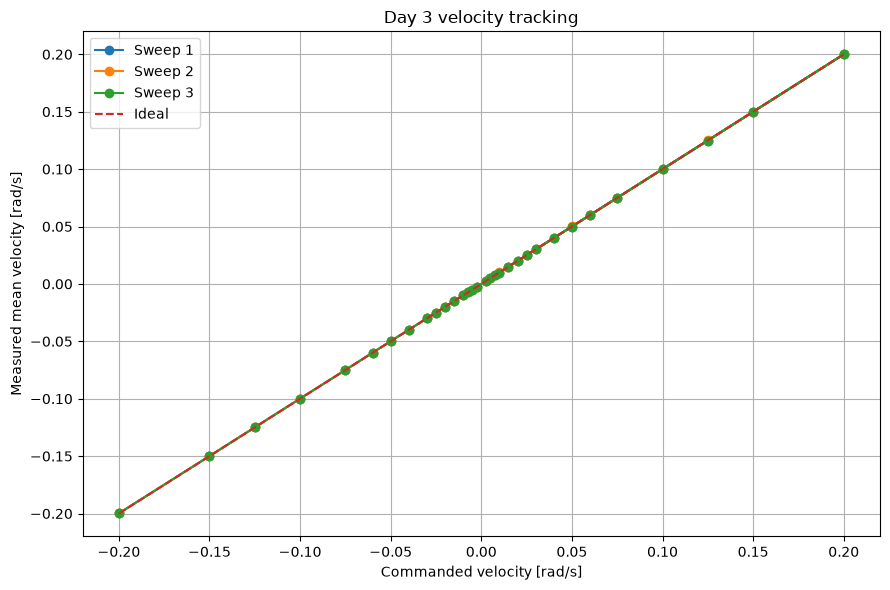

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/01_velocity_tracking.png


In [5]:
plt.figure(figsize=(9, 6))

for sweep, group in per_point.groupby("sweep"):
    moving = group[np.abs(group["command_velocity_rad_s"]) > 1e-12]
    plt.plot(
        moving["command_velocity_rad_s"],
        moving["mean_velocity_rad_s"],
        marker="o",
        label=f"Sweep {sweep}",
    )

lims = [
    per_point["command_velocity_rad_s"].min(),
    per_point["command_velocity_rad_s"].max(),
]
plt.plot(lims, lims, linestyle="--", label="Ideal")
plt.xlabel("Commanded velocity [rad/s]")
plt.ylabel("Measured mean velocity [rad/s]")
plt.title("Day 3 velocity tracking")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "01_velocity_tracking.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


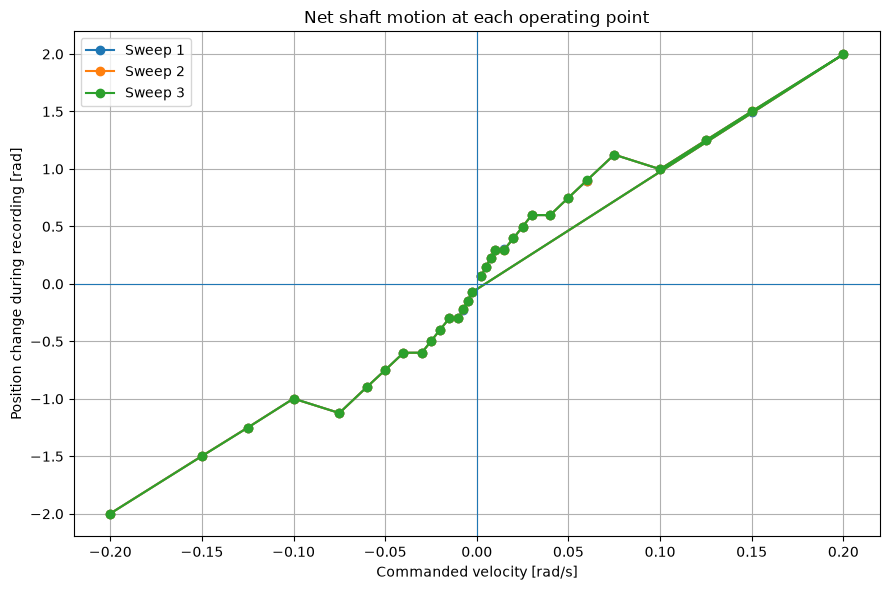

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/02_position_travel.png


In [6]:
plt.figure(figsize=(9, 6))

for sweep, group in per_point.groupby("sweep"):
    moving = group[np.abs(group["command_velocity_rad_s"]) > 1e-12]
    plt.plot(
        moving["command_velocity_rad_s"],
        moving["position_change_rad"],
        marker="o",
        label=f"Sweep {sweep}",
    )

plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Commanded velocity [rad/s]")
plt.ylabel("Position change during recording [rad]")
plt.title("Net shaft motion at each operating point")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "02_position_travel.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 5. Individual low-speed friction curves

Sweeps are plotted separately to expose startup, thermal, lubrication, position-dependent, or history-dependent effects.


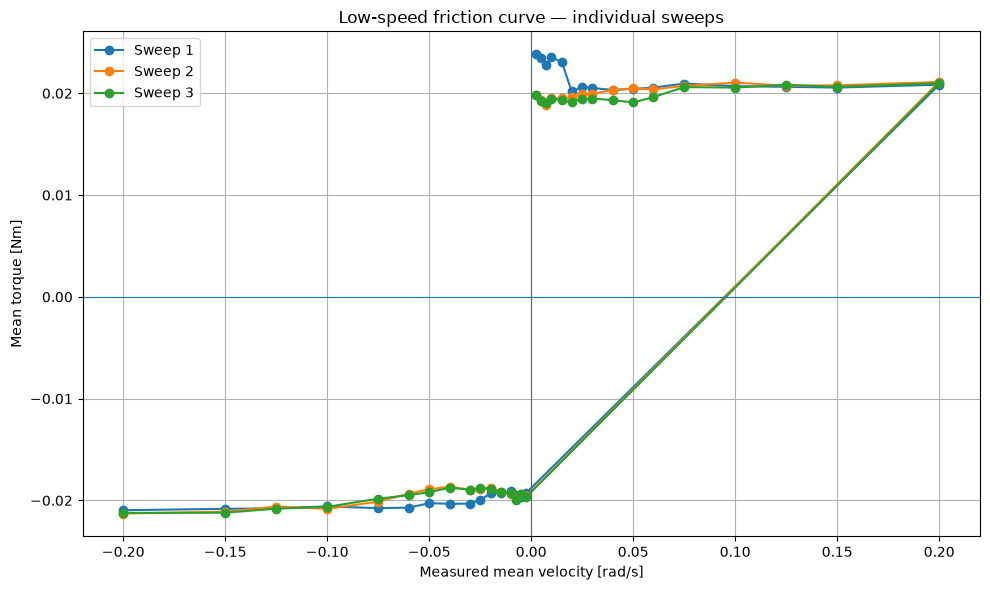

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/03_low_speed_individual_sweeps.png


In [7]:
plt.figure(figsize=(10, 6))

for sweep, group in per_point.groupby("sweep"):
    moving = group[np.abs(group["command_velocity_rad_s"]) > 1e-12]
    plt.plot(
        moving["mean_velocity_rad_s"],
        moving["mean_torque_Nm"],
        marker="o",
        label=f"Sweep {sweep}",
    )

plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Measured mean velocity [rad/s]")
plt.ylabel("Mean torque [Nm]")
plt.title("Low-speed friction curve — individual sweeps")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "03_low_speed_individual_sweeps.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 6. Combined summary across sweeps

The combined summary averages block means so longer recording windows do not receive artificially greater weight.


In [8]:
combined = (
    per_point.groupby("command_velocity_rad_s", as_index=False)
    .agg(
        n_blocks=("mean_torque_Nm", "size"),
        mean_velocity_rad_s=("mean_velocity_rad_s", "mean"),
        std_velocity_between_sweeps=("mean_velocity_rad_s", "std"),
        mean_velocity_std_within=("std_velocity_rad_s", "mean"),
        mean_torque_Nm=("mean_torque_Nm", "mean"),
        std_torque_between_sweeps=("mean_torque_Nm", "std"),
        mean_torque_std_within=("std_torque_Nm", "mean"),
        mean_position_change_rad=("position_change_rad", "mean"),
    )
)

combined["velocity_error_rad_s"] = (
    combined["mean_velocity_rad_s"] - combined["command_velocity_rad_s"]
)

display(combined)
combined.to_csv(OUTPUT_DIR / "combined_summary.csv", index=False)


,command_velocity_rad_s,n_blocks,mean_velocity_rad_s,std_velocity_between_sweeps,mean_velocity_std_within,mean_torque_Nm,std_torque_between_sweeps,mean_torque_std_within,mean_position_change_rad,velocity_error_rad_s
0,-0.2000,3,-0.199860,0.000023,0.008462,-0.021162,0.000173,0.014149,-1.997835,0.000140
1,-0.1500,3,-0.149969,0.000045,0.007909,-0.021050,0.000199,0.014000,-1.497807,0.000031
2,-0.1250,3,-0.124966,0.000061,0.007790,-0.020731,0.000111,0.013631,-1.250357,0.000034
3,-0.1000,3,-0.099906,0.000021,0.007511,-0.020685,0.000132,0.013944,-0.997904,0.000094
4,-0.0750,3,-0.074969,0.000038,0.007321,-0.020235,0.000477,0.013596,-1.123600,0.000031
5,-0.0600,3,-0.059930,0.000019,0.006979,-0.019846,0.000752,0.013473,-0.897202,0.000070
6,-0.0500,3,-0.049892,0.000034,0.006658,-0.019457,0.000718,0.013197,-0.749890,0.000108
7,-0.0400,3,-0.039920,0.000057,0.006536,-0.019242,0.000945,0.013172,-0.599347,0.000080
8,-0.0300,3,-0.029956,0.000079,0.006306,-0.019415,0.000781,0.013027,-0.598919,0.000044
9,-0.0250,3,-0.024947,0.000049,0.006065,-0.019195,0.000655,0.013250,-0.498543,0.000053


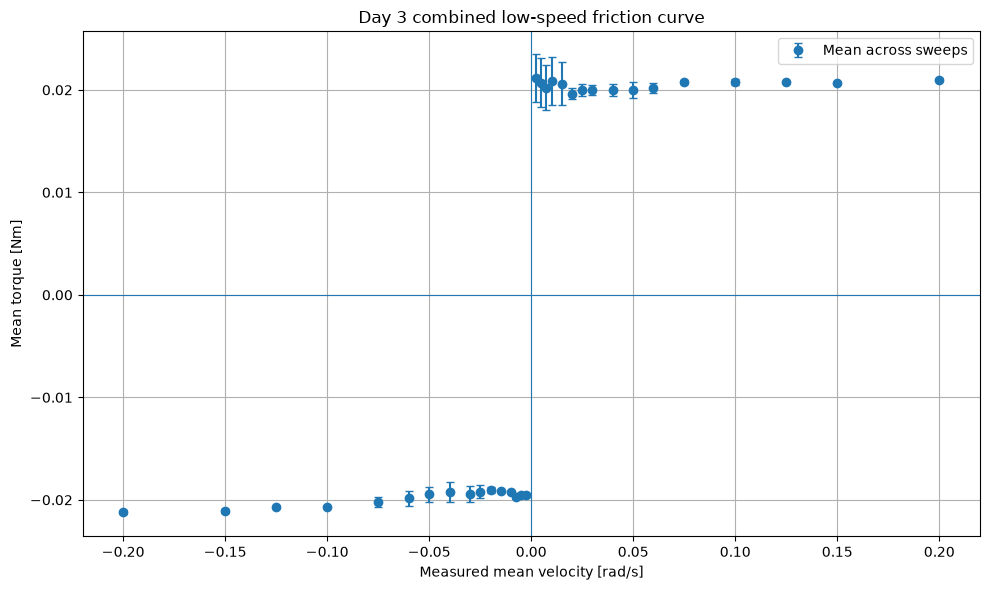

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/04_low_speed_combined.png


In [9]:
moving_combined = combined[
    np.abs(combined["command_velocity_rad_s"]) > 1e-12
].copy()

plt.figure(figsize=(10, 6))
plt.errorbar(
    moving_combined["mean_velocity_rad_s"],
    moving_combined["mean_torque_Nm"],
    yerr=moving_combined["std_torque_between_sweeps"],
    fmt="o",
    capsize=3,
    label="Mean across sweeps",
)
plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Measured mean velocity [rad/s]")
plt.ylabel("Mean torque [Nm]")
plt.title("Day 3 combined low-speed friction curve")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "04_low_speed_combined.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 7. Positive / negative symmetry

In [10]:
positive = moving_combined[
    moving_combined["command_velocity_rad_s"] > 0
].copy()
negative = moving_combined[
    moving_combined["command_velocity_rad_s"] < 0
].copy()

positive["abs_command"] = positive["command_velocity_rad_s"].abs()
negative["abs_command"] = negative["command_velocity_rad_s"].abs()

symmetry = positive.merge(
    negative,
    on="abs_command",
    suffixes=("_pos", "_neg"),
)

symmetry["torque_sum_Nm"] = (
    symmetry["mean_torque_Nm_pos"] + symmetry["mean_torque_Nm_neg"]
)
symmetry["torque_magnitude_difference_Nm"] = (
    symmetry["mean_torque_Nm_pos"].abs()
    - symmetry["mean_torque_Nm_neg"].abs()
)

display(symmetry[
    [
        "abs_command",
        "mean_torque_Nm_pos",
        "mean_torque_Nm_neg",
        "torque_sum_Nm",
        "torque_magnitude_difference_Nm",
    ]
])

symmetry.to_csv(
    OUTPUT_DIR / "positive_negative_symmetry.csv",
    index=False,
)


,abs_command,mean_torque_Nm_pos,mean_torque_Nm_neg,torque_sum_Nm,torque_magnitude_difference_Nm
0,0.0025,0.021162,-0.019510,0.001652,0.001652
1,0.0050,0.020696,-0.019482,0.001214,0.001214
2,0.0075,0.020205,-0.019748,0.000456,0.000456
3,0.0100,0.020842,-0.019234,0.001608,0.001608
4,0.0150,0.020623,-0.019180,0.001442,0.001442
5,0.0200,0.019632,-0.018998,0.000634,0.000634
6,0.0250,0.019993,-0.019195,0.000797,0.000797
7,0.0300,0.019976,-0.019415,0.000562,0.000562
8,0.0400,0.019998,-0.019242,0.000756,0.000756
9,0.0500,0.020000,-0.019457,0.000543,0.000543


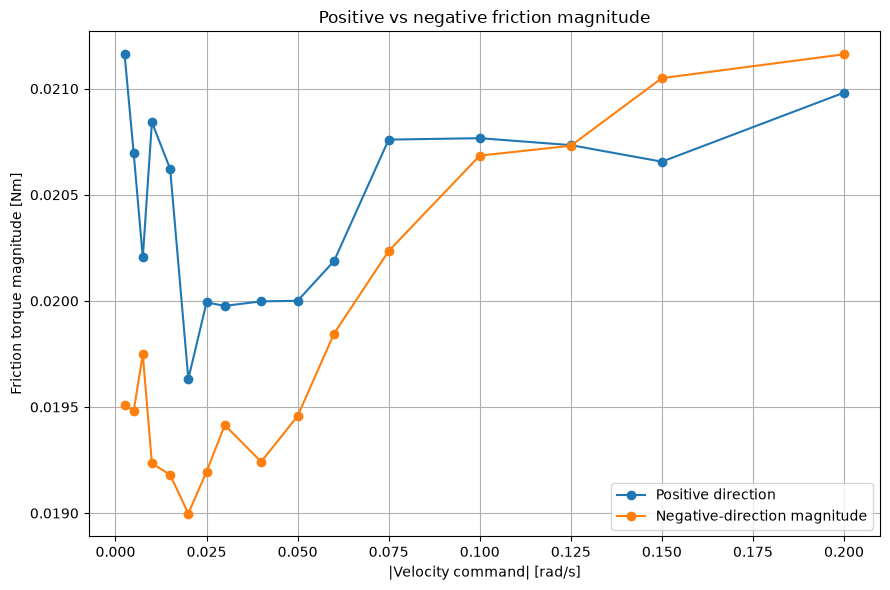

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/05_directional_symmetry.png


In [11]:
plt.figure(figsize=(9, 6))
plt.plot(
    symmetry["abs_command"],
    symmetry["mean_torque_Nm_pos"],
    marker="o",
    label="Positive direction",
)
plt.plot(
    symmetry["abs_command"],
    -symmetry["mean_torque_Nm_neg"],
    marker="o",
    label="Negative-direction magnitude",
)
plt.xlabel("|Velocity command| [rad/s]")
plt.ylabel("Friction torque magnitude [Nm]")
plt.title("Positive vs negative friction magnitude")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "05_directional_symmetry.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 8. Zero-speed history dependence

Zero-speed torque is analyzed separately because static friction is not represented well by a single-valued smooth friction curve.


In [12]:
zero_blocks = per_point[
    np.abs(per_point["command_velocity_rad_s"]) <= 1e-12
].copy()

zero_blocks["zero_context"] = np.select(
    [
        zero_blocks["previous_command_velocity_rad_s"] > 0,
        zero_blocks["previous_command_velocity_rad_s"] < 0,
    ],
    [
        "after positive motion",
        "after negative motion",
    ],
    default="initial / previous zero",
)

display(zero_blocks[
    [
        "sweep",
        "point",
        "previous_command_velocity_rad_s",
        "mean_velocity_rad_s",
        "mean_torque_Nm",
        "std_torque_Nm",
        "zero_context",
    ]
])

zero_blocks.to_csv(
    OUTPUT_DIR / "zero_speed_history.csv",
    index=False,
)


,sweep,point,previous_command_velocity_rad_s,mean_velocity_rad_s,mean_torque_Nm,std_torque_Nm,zero_context
0,1,1,0.0,0.000051,-0.022452,0.004196,initial / previous zero
17,1,18,0.2,0.000113,-0.000571,0.002404,after positive motion
34,1,35,-0.2,-0.000082,-0.010716,0.006194,after negative motion
35,2,1,0.0,-0.000204,-0.010280,0.006255,initial / previous zero
52,2,18,0.2,-0.000012,-0.000828,0.002839,after positive motion
69,2,35,-0.2,-0.000096,-0.010653,0.005660,after negative motion
70,3,1,0.0,-0.000013,-0.010564,0.005788,initial / previous zero
87,3,18,0.2,-0.000030,-0.000650,0.002439,after positive motion
104,3,35,-0.2,-0.000140,-0.013482,0.004914,after negative motion


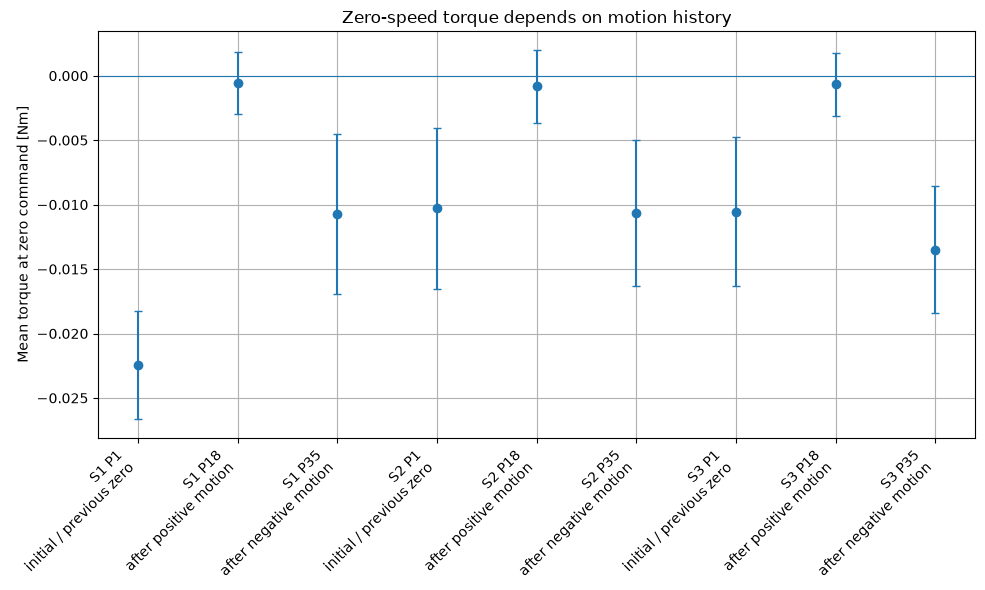

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/06_zero_speed_history.png


In [13]:
plt.figure(figsize=(10, 6))
x = np.arange(len(zero_blocks))

plt.errorbar(
    x,
    zero_blocks["mean_torque_Nm"],
    yerr=zero_blocks["std_torque_Nm"],
    fmt="o",
    capsize=3,
)

labels = [
    f"S{s} P{p}\n{ctx}"
    for s, p, ctx in zip(
        zero_blocks["sweep"],
        zero_blocks["point"],
        zero_blocks["zero_context"],
    )
]

plt.xticks(x, labels, rotation=45, ha="right")
plt.axhline(0.0, linewidth=0.8)
plt.ylabel("Mean torque at zero command [Nm]")
plt.title("Zero-speed torque depends on motion history")
plt.grid(True)
plt.tight_layout()

path = OUTPUT_DIR / "06_zero_speed_history.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 9. Sweep-to-sweep repeatability

Sweep 1 is compared with sweeps 2–3 rather than discarded automatically.


In [14]:
sweep_pivot = per_point[
    np.abs(per_point["command_velocity_rad_s"]) > 1e-12
].pivot_table(
    index="command_velocity_rad_s",
    columns="sweep",
    values="mean_torque_Nm",
)

sweep_pivot.columns = [
    f"sweep_{int(c)}_torque_Nm"
    for c in sweep_pivot.columns
]

display(sweep_pivot)
sweep_pivot.to_csv(OUTPUT_DIR / "sweep_repeatability.csv")

if {1, 2, 3}.issubset(set(per_point["sweep"].unique())):
    s1 = per_point[
        (per_point["sweep"] == 1)
        & (np.abs(per_point["command_velocity_rad_s"]) > 1e-12)
    ].set_index("command_velocity_rad_s")

    later = (
        per_point[
            (per_point["sweep"].isin([2, 3]))
            & (np.abs(per_point["command_velocity_rad_s"]) > 1e-12)
        ]
        .groupby("command_velocity_rad_s")["mean_torque_Nm"]
        .mean()
    )

    compare = pd.DataFrame({
        "sweep1": s1["mean_torque_Nm"],
        "mean_sweeps2_3": later,
    })
    compare["difference_Nm"] = (
        compare["sweep1"] - compare["mean_sweeps2_3"]
    )

    display(compare)
    print(
        "Mean absolute difference, sweep 1 vs mean sweeps 2–3:",
        compare["difference_Nm"].abs().mean(),
        "Nm",
    )


,sweep_1_torque_Nm,sweep_2_torque_Nm,sweep_3_torque_Nm
command_velocity_rad_s,,,
-0.2000,-0.020966,-0.021291,-0.021229
-0.1500,-0.020828,-0.021109,-0.021213
-0.1250,-0.020777,-0.020605,-0.020812
-0.1000,-0.020589,-0.020835,-0.020630
-0.0750,-0.020762,-0.020114,-0.019830
-0.0600,-0.020710,-0.019340,-0.019488
-0.0500,-0.020270,-0.018910,-0.019192
-0.0400,-0.020331,-0.018643,-0.018751
-0.0300,-0.020316,-0.018975,-0.018953


,sweep1,mean_sweeps2_3,difference_Nm
command_velocity_rad_s,,,
-0.2000,-0.020966,-0.021260,0.000295
-0.1500,-0.020828,-0.021161,0.000333
-0.1250,-0.020777,-0.020708,-0.000069
-0.1000,-0.020589,-0.020732,0.000143
-0.0750,-0.020762,-0.019972,-0.000790
-0.0600,-0.020710,-0.019414,-0.001296
-0.0500,-0.020270,-0.019051,-0.001219
-0.0400,-0.020331,-0.018697,-0.001634
-0.0300,-0.020316,-0.018964,-0.001352


Mean absolute difference, sweep 1 vs mean sweeps 2–3: 0.0010882381124196095 Nm


# 10. Friction models

Free model:

`tau = sign(w) * [tau_c + (tau_s - tau_c) * exp(-(abs(w)/w_s)^n)] + b*w + offset`

The Day-2-constrained fit fixes `tau_c` and `b` from the broad-range experiment and estimates the low-speed nonlinear parameters from Day 3.


In [15]:
DAY2_TAU_C = 0.01990326
DAY2_B = 0.00277339
DAY2_OFFSET = -0.00028673

fit_data = moving_combined.copy()
w = fit_data["mean_velocity_rad_s"].to_numpy()
tau = fit_data["mean_torque_Nm"].to_numpy()


def stribeck_model(w, tau_c, tau_s, w_s, b, offset, n):
    magnitude = (
        tau_c
        + (tau_s - tau_c)
        * np.exp(-(np.abs(w) / w_s) ** n)
    )
    return np.sign(w) * magnitude + b * w + offset


def r_squared(y, y_hat):
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1.0 - ss_res / ss_tot


def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))


## 11. Free Stribeck fit

In [16]:
free_initial = [
    DAY2_TAU_C,
    0.025,
    0.03,
    DAY2_B,
    0.0,
    2.0,
]

free_lower = [
    0.0,
    0.0,
    0.0001,
    0.0,
    -0.05,
    0.2,
]

free_upper = [
    0.1,
    0.1,
    1.0,
    0.05,
    0.05,
    10.0,
]

free_params, free_cov = curve_fit(
    stribeck_model,
    w,
    tau,
    p0=free_initial,
    bounds=(free_lower, free_upper),
    maxfev=200000,
)

free_prediction = stribeck_model(w, *free_params)
free_r2 = r_squared(tau, free_prediction)
free_rmse = rmse(tau, free_prediction)

free_names = [
    "tau_c [Nm]",
    "tau_s [Nm]",
    "w_s [rad/s]",
    "b [Nm/(rad/s)]",
    "offset [Nm]",
    "n [-]",
]

free_table = pd.DataFrame({
    "parameter": free_names,
    "value": free_params,
    "std_error": np.sqrt(np.diag(free_cov)),
})

display(free_table)
print("Free-fit R²:", free_r2)
print("Free-fit RMSE:", free_rmse, "Nm")


,parameter,value,std_error
0,tau_c [Nm],0.019401,0.000162
1,tau_s [Nm],0.020189,0.000270
2,w_s [rad/s],0.013073,0.004542
3,b [Nm/(rad/s)],0.009758,0.001597
4,offset [Nm],0.000314,0.000069
5,n [-],2.663517,3.148460


Free-fit R²: 0.9996959505497217
Free-fit RMSE: 0.0003512741209026372 Nm


## 12. Day-2-constrained Stribeck fit

This fit fixes:

- `tau_c = 0.01990326 Nm`
- `b = 0.00277339 Nm/(rad/s)`

and estimates `tau_s`, `w_s`, `offset`, and `n`.

The lower bound enforces `tau_s >= tau_c` for a classical Stribeck interpretation.


In [17]:
def constrained_stribeck_model(w, tau_s, w_s, offset, n):
    return stribeck_model(
        w,
        DAY2_TAU_C,
        tau_s,
        w_s,
        DAY2_B,
        offset,
        n,
    )


constrained_params, constrained_cov = curve_fit(
    constrained_stribeck_model,
    w,
    tau,
    p0=[0.025, 0.03, 0.0, 2.0],
    bounds=(
        [DAY2_TAU_C, 0.0001, -0.05, 0.2],
        [0.1, 1.0, 0.05, 10.0],
    ),
    maxfev=200000,
)

constrained_prediction = constrained_stribeck_model(
    w,
    *constrained_params,
)

constrained_r2 = r_squared(tau, constrained_prediction)
constrained_rmse = rmse(tau, constrained_prediction)

constrained_names = [
    "tau_s [Nm]",
    "w_s [rad/s]",
    "offset [Nm]",
    "n [-]",
]

constrained_table = pd.DataFrame({
    "parameter": constrained_names,
    "value": constrained_params,
    "std_error": np.sqrt(np.diag(constrained_cov)),
})

display(constrained_table)

print("Fixed Day 2 tau_c:", DAY2_TAU_C, "Nm")
print("Fixed Day 2 b:", DAY2_B, "Nm/(rad/s)")
print("Constrained-fit R²:", constrained_r2)
print("Constrained-fit RMSE:", constrained_rmse, "Nm")


,parameter,value,std_error
0,tau_s [Nm],0.020622,0.005306
1,w_s [rad/s],0.003909,0.026520
2,offset [Nm],0.000314,0.000090
3,n [-],1.277906,9.452306


Fixed Day 2 tau_c: 0.01990326 Nm
Fixed Day 2 b: 0.00277339 Nm/(rad/s)
Constrained-fit R²: 0.9994384662490288
Constrained-fit RMSE: 0.00047737753393675486 Nm


## 13. Fit comparison

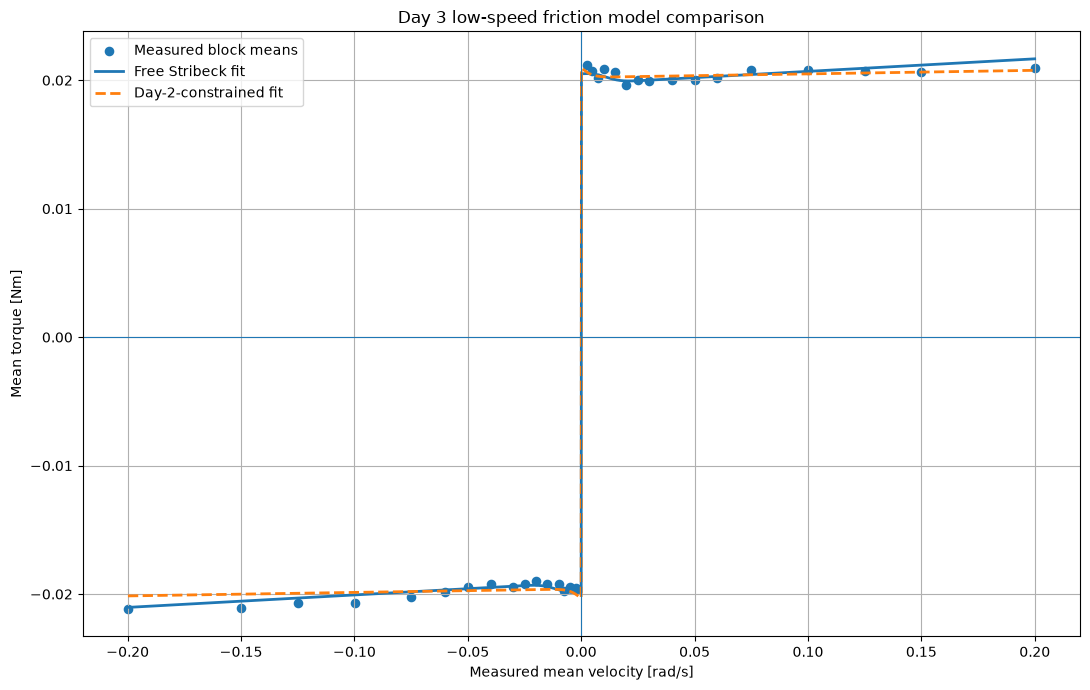

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/07_stribeck_model_comparison.png


In [18]:
w_plot = np.linspace(
    fit_data["mean_velocity_rad_s"].min(),
    fit_data["mean_velocity_rad_s"].max(),
    3000,
)

plt.figure(figsize=(11, 7))

plt.scatter(w, tau, s=35, label="Measured block means")

plt.plot(
    w_plot,
    stribeck_model(w_plot, *free_params),
    linewidth=2,
    label="Free Stribeck fit",
)

plt.plot(
    w_plot,
    constrained_stribeck_model(w_plot, *constrained_params),
    linewidth=2,
    linestyle="--",
    label="Day-2-constrained fit",
)

plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Measured mean velocity [rad/s]")
plt.ylabel("Mean torque [Nm]")
plt.title("Day 3 low-speed friction model comparison")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "07_stribeck_model_comparison.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 14. Residual analysis

A high R² is not sufficient. Residuals should not retain a strong systematic velocity-dependent structure.


,command_velocity_rad_s,mean_velocity_rad_s,mean_torque_Nm,free_prediction_Nm,free_residual_Nm,constrained_prediction_Nm,constrained_residual_Nm
0,-0.2000,-0.199860,-0.021162,-0.021038,-0.000124,-0.020144,-0.001019
1,-0.1500,-0.149969,-0.021050,-0.020551,-0.000499,-0.020005,-0.001045
2,-0.1250,-0.124966,-0.020731,-0.020307,-0.000424,-0.019936,-0.000795
3,-0.1000,-0.099906,-0.020685,-0.020062,-0.000622,-0.019866,-0.000818
4,-0.0750,-0.074969,-0.020235,-0.019819,-0.000416,-0.019797,-0.000438
5,-0.0600,-0.059930,-0.019846,-0.019672,-0.000174,-0.019756,-0.000090
6,-0.0500,-0.049892,-0.019457,-0.019574,0.000117,-0.019728,0.000270
7,-0.0400,-0.039920,-0.019242,-0.019477,0.000235,-0.019700,0.000458
8,-0.0300,-0.029956,-0.019415,-0.019380,-0.000035,-0.019672,0.000258
9,-0.0250,-0.024947,-0.019195,-0.019334,0.000138,-0.019659,0.000463


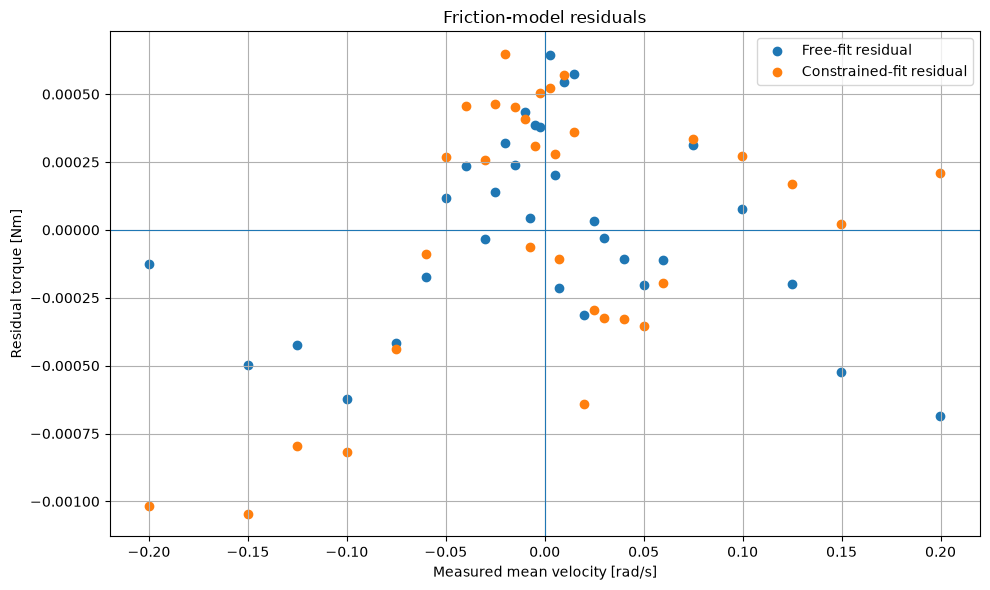

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/08_model_residuals.png


In [19]:
fit_results = fit_data[
    [
        "command_velocity_rad_s",
        "mean_velocity_rad_s",
        "mean_torque_Nm",
    ]
].copy()

fit_results["free_prediction_Nm"] = free_prediction
fit_results["free_residual_Nm"] = tau - free_prediction
fit_results["constrained_prediction_Nm"] = constrained_prediction
fit_results["constrained_residual_Nm"] = tau - constrained_prediction

display(fit_results)
fit_results.to_csv(OUTPUT_DIR / "fit_residuals.csv", index=False)

plt.figure(figsize=(10, 6))
plt.scatter(
    w,
    fit_results["free_residual_Nm"],
    label="Free-fit residual",
)
plt.scatter(
    w,
    fit_results["constrained_residual_Nm"],
    label="Constrained-fit residual",
)
plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Measured mean velocity [rad/s]")
plt.ylabel("Residual torque [Nm]")
plt.title("Friction-model residuals")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "08_model_residuals.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 15. Constrained-fit friction-component decomposition

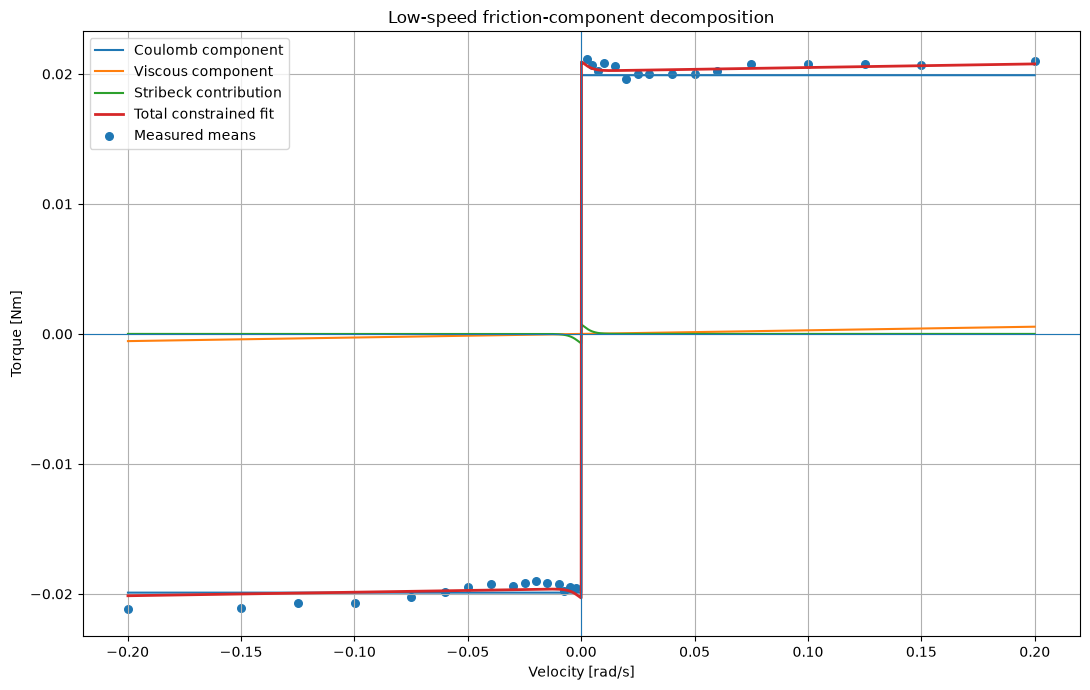

Saved: /home/uexpj/ros2_ws/day3_low_speed_analysis/09_friction_components.png


In [20]:
tau_s_c, w_s_c, offset_c, n_c = constrained_params

sign_plot = np.sign(w_plot)
abs_plot = np.abs(w_plot)

coulomb_component = DAY2_TAU_C * sign_plot
viscous_component = DAY2_B * w_plot

stribeck_component = (
    (tau_s_c - DAY2_TAU_C)
    * np.exp(-(abs_plot / w_s_c) ** n_c)
    * sign_plot
)

total_component = (
    coulomb_component
    + viscous_component
    + stribeck_component
    + offset_c
)

plt.figure(figsize=(11, 7))
plt.plot(w_plot, coulomb_component, label="Coulomb component")
plt.plot(w_plot, viscous_component, label="Viscous component")
plt.plot(w_plot, stribeck_component, label="Stribeck contribution")
plt.plot(w_plot, total_component, linewidth=2, label="Total constrained fit")
plt.scatter(w, tau, s=30, label="Measured means")

plt.axhline(0.0, linewidth=0.8)
plt.axvline(0.0, linewidth=0.8)
plt.xlabel("Velocity [rad/s]")
plt.ylabel("Torque [Nm]")
plt.title("Low-speed friction-component decomposition")
plt.grid(True)
plt.legend()
plt.tight_layout()

path = OUTPUT_DIR / "09_friction_components.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)


## 16. Model comparison table

In [21]:
model_comparison = pd.DataFrame([
    {
        "model": "Free Stribeck",
        "tau_c_Nm": free_params[0],
        "tau_s_Nm": free_params[1],
        "w_s_rad_s": free_params[2],
        "b_Nm_per_rad_s": free_params[3],
        "offset_Nm": free_params[4],
        "n": free_params[5],
        "R2": free_r2,
        "RMSE_Nm": free_rmse,
    },
    {
        "model": "Day-2-constrained Stribeck",
        "tau_c_Nm": DAY2_TAU_C,
        "tau_s_Nm": constrained_params[0],
        "w_s_rad_s": constrained_params[1],
        "b_Nm_per_rad_s": DAY2_B,
        "offset_Nm": constrained_params[2],
        "n": constrained_params[3],
        "R2": constrained_r2,
        "RMSE_Nm": constrained_rmse,
    },
])

display(model_comparison)
model_comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False,
)


,model,tau_c_Nm,tau_s_Nm,w_s_rad_s,b_Nm_per_rad_s,offset_Nm,n,R2,RMSE_Nm
0,Free Stribeck,0.019401,0.020189,0.013073,0.009758,0.000314,2.663517,0.999696,0.000351
1,Day-2-constrained Stribeck,0.019903,0.020622,0.003909,0.002773,0.000314,1.277906,0.999438,0.000477


# 17. Interpretation

## Dataset quality

The Day 3 acquisition is complete and suitable for low-speed friction analysis.

- All three sweeps are present and complete.
- All 35 intended points are present in every sweep.
- The dataset contains 374,436 recorded samples with no missing values.
- The median sampling interval is approximately `0.005 s`, corresponding to an effective sampling rate of approximately `200 Hz`.
- Even the smallest commands produce sustained net shaft motion. For example, at `+0.0025 rad/s`, the shaft travels about `0.072 rad` during the recording interval, and at `+0.005 rad/s` it travels about `0.147 rad`.
- At the very smallest commands, instantaneous velocity variation is large compared with the command magnitude. At `0.0025 rad/s`, the velocity standard deviation is approximately `0.0036–0.0040 rad/s`, which is larger than the commanded value itself. However, the mean velocity remains close to the command and the accumulated position change confirms sustained motion.

**Interpretation:** The lowest-speed points are valid for steady-state mean-friction estimation, but they should not be interpreted as perfectly constant instantaneous velocity operation.

---

## Repeatability

Sweeps 2 and 3 are substantially more similar to each other than either is to sweep 1 in the very-low-speed positive region.

The main difference appears near approximately `+0.0025` to `+0.015 rad/s`, where sweep 1 requires roughly `0.023–0.024 Nm`, while sweeps 2 and 3 are closer to `0.019–0.020 Nm`.

The mean absolute torque difference between sweep 1 and the mean of sweeps 2–3 is approximately:

`0.00109 Nm`

This difference is significant relative to the magnitude of the low-speed nonlinear effect being investigated.

**Interpretation:** Sweep 1 should not be discarded automatically. The systematic difference is evidence of a non-stationary effect that may include startup/thermal settling, lubrication redistribution, shaft-position dependence, controller-state effects, or motion-history dependence. Because the current experiment was not designed to isolate those mechanisms, the exact cause cannot be determined from this dataset alone.

---

## Low-speed friction behavior

A repeatable nonlinear low-speed friction region is visible.

The torque magnitude is relatively high extremely close to zero velocity, decreases over approximately the first few hundredths of a radian per second, and then begins to increase again.

On the positive side, the lowest values occur roughly in the `0.0075–0.05 rad/s` region depending on sweep. The negative side shows a similar shallow low-speed structure.

At higher low-speed points, torque magnitude increases again as the viscous contribution becomes more important.

**Interpretation:** The data are consistent with a low-speed friction transition that cannot be explained by Coulomb plus viscous friction alone. However, the exact location and shape of the minimum vary enough between sweeps that the transition should not yet be reduced to a single precise characteristic velocity.

---

## Positive / negative symmetry

Positive and negative friction are broadly symmetric, particularly from roughly `0.075–0.10 rad/s` upward.

At the smallest velocities, a small directional asymmetry remains. The positive direction often requires roughly `1–1.6 mNm` more torque magnitude than the corresponding negative direction at several very-low-speed points.

**Interpretation:** A symmetric friction model captures the dominant behavior, but the low-speed asymmetry is not negligible relative to the Stribeck-scale effect and may be related to history, preload, motor construction, position dependence, or controller effects.

---

## Stribeck identification

### Free fit

The fully free Stribeck fit gives approximately:

- `tau_c = 0.019401 Nm`
- `tau_s = 0.020189 Nm`
- `w_s = 0.013073 rad/s`
- `b = 0.009758 Nm/(rad/s)`
- `offset = 0.000314 Nm`
- `n = 2.6635`
- `R² = 0.999696`
- `RMSE = 0.000351 Nm`

The fit is numerically excellent and gives the physically sensible ordering:

`tau_s > tau_c`

However, the estimated viscous coefficient is much larger than the broad-range Day 2 value of approximately:

`0.002773 Nm/(rad/s)`

**Interpretation:** Over the narrow Day 3 velocity interval, the optimizer is using the viscous term partly to reproduce the local curve shape. Therefore the free-fit value of `b` should not be interpreted as the physical viscous drag coefficient of the motor.

### Day-2-constrained fit

The constrained fit fixes the broad-range Day 2 estimates:

- `tau_c = 0.019903 Nm`
- `b = 0.002773 Nm/(rad/s)`

and estimates:

- `tau_s = 0.020622 Nm`
- `w_s = 0.003909 rad/s`
- `offset = 0.000314 Nm`
- `n = 1.2779`
- `R² = 0.999438`
- `RMSE = 0.000477 Nm`

This fit is more physically defensible because the Coulomb and viscous terms come from a much broader velocity range.

However, the fitted low-speed parameters have large uncertainty. The approximate standard errors are:

- `tau_s: ±0.00531 Nm`
- `w_s: ±0.02652 rad/s`
- `n: ±9.45`

These uncertainties are very large relative to the fitted values.

**Interpretation:** Day 3 supports the existence of a low-speed nonlinear friction region, but it does not yet support precise identification of a unique Stribeck characteristic velocity or exponent.

---

## Residuals

Both the free and constrained models achieve very high `R²`, but the residuals retain visible velocity-dependent structure.

**Interpretation:** A classical symmetric Coulomb + viscous + Stribeck model captures the dominant trend, but it does not explain all observed behavior. The remaining structure is consistent with the presence of additional effects such as directional asymmetry, history dependence, position dependence, or non-stationary behavior.

---

## Zero-speed behavior

The zero-speed blocks are strongly history-dependent.

The measured torque at zero command differs depending on whether the motor arrived at zero after positive motion, after negative motion, or from an initial condition.

In particular, zero-speed blocks after negative motion remain noticeably negative, while zero after positive motion is much closer to zero in several cases.

**Interpretation:** Zero-speed torque should not be represented as a single point on a memoryless friction-versus-velocity curve. This behavior is evidence that static friction, pre-sliding behavior, holding torque, or hysteresis must be investigated separately.

---

## Overall interpretation

The Day 3 experiment successfully resolves a genuine low-speed nonlinear friction region more clearly than Day 2.

The most defensible conclusions are:

1. Coulomb friction remains approximately `0.020 Nm`.
2. Broad-range viscous drag remains approximately `0.0028 Nm/(rad/s)` based on Day 2.
3. A nonlinear low-speed friction transition exists.
4. The exact Stribeck parameters are not yet robustly identifiable.
5. Sweep-to-sweep differences are of the same order as the low-speed nonlinear effect.
6. Zero-speed torque is strongly dependent on previous motion.
7. A purely memoryless symmetric friction model is therefore incomplete in the very-low-speed region.

The next experiment should focus on **hysteresis and motion-history dependence**, rather than simply adding more steady-state points at still finer velocity spacing.


# 18. Provisional conclusion

**Observation:**  
The high-resolution Day 3 experiment reveals a repeatable nonlinear low-speed friction region. The torque magnitude is elevated very close to zero velocity, decreases over approximately the first few hundredths of rad/s, and subsequently increases again. Sweeps 2 and 3 agree closely, while sweep 1 shows a noticeable positive-direction offset at the smallest velocities. The mean absolute difference between sweep 1 and the mean of sweeps 2–3 is approximately **0.00109 Nm**, which is large enough relative to the low-speed nonlinear effect that it should not be ignored.

**Model result:**  
The fully free Stribeck fit gives

- `tau_c = 0.019401 Nm`
- `tau_s = 0.020189 Nm`
- `w_s = 0.013073 rad/s`
- `b = 0.009758 Nm/(rad/s)`
- `offset = 0.000314 Nm`
- `n = 2.6635`
- `R² = 0.999696`
- `RMSE = 0.000351 Nm`

The fit is numerically excellent and gives the physically sensible ordering `tau_s > tau_c`. However, the fitted viscous coefficient is much larger than the broad-range Day 2 estimate (`0.002773 Nm/(rad/s)`). Over the narrow Day 3 velocity interval, this indicates parameter coupling: the optimizer is using the viscous term partly to reproduce low-speed curve shape rather than identifying the true broad-range viscous drag.

The Day-2-constrained Stribeck fit keeps

- `tau_c = 0.019903 Nm`
- `b = 0.002773 Nm/(rad/s)`

fixed and gives

- `tau_s = 0.020622 Nm`
- `w_s = 0.003909 rad/s`
- `offset = 0.000314 Nm`
- `n = 1.2779`
- `R² = 0.999438`
- `RMSE = 0.000477 Nm`

This model is more physically defensible because Coulomb and viscous friction were identified over the much broader Day 2 speed range. However, the uncertainty of the remaining Stribeck parameters is large: approximately `±0.00531 Nm` for `tau_s`, `±0.02652 rad/s` for `w_s`, and `±9.45` for `n`. Therefore the current data support the existence of a low-speed nonlinear friction region, but do **not** yet support precise identification of the characteristic Stribeck velocity or exponent.

**Limitations:**  

1. At the smallest velocity commands, the instantaneous velocity standard deviation is comparable to or larger than the command magnitude. The mean velocity and accumulated shaft travel are nevertheless consistent with sustained motion, so block-mean friction estimates remain useful.
2. Sweep 1 differs systematically from sweeps 2 and 3 near the smallest positive velocities. Possible explanations include startup or thermal settling, lubrication redistribution, shaft-position dependence, controller-state effects, or other motion-history dependence.
3. Positive and negative friction are broadly symmetric, but small directional differences remain in the very-low-speed region. These differences are not negligible relative to the magnitude of the Stribeck effect being identified.
4. Exact zero-speed torque is strongly history-dependent and should not be represented as a single point on a memoryless friction-versus-velocity curve.
5. The residual plots retain velocity-dependent structure, so a classical symmetric Coulomb + viscous + Stribeck model captures the dominant trend but does not explain all observed behavior.

**Decision:**  
The next experiment should prioritize **motion-history and hysteresis effects**, rather than simply adding more steady-state velocity points. The next measurement should compare ascending and descending low-speed trajectories using the same velocity range, while preserving direction and previous-command information. A separate breakaway/static-friction experiment should follow if the hysteresis test confirms meaningful history dependence.

The current Day 3 result is therefore best interpreted as: **the low-speed nonlinear region is real and reproducible, but its behavior cannot yet be reduced confidently to a unique classical Stribeck parameter set without considering history-dependent effects.**


In [22]:
print("========================================")
print("DAY 3 LOW-SPEED ANALYSIS SUMMARY")
print("========================================")
print()

print("Dataset:", DATA_FILE)
print(f"Rows: {len(df)}")
print(f"Sweeps: {df['sweep'].nunique()}")
print(f"Unique commanded velocities: {df['command_velocity_rad_s'].nunique()}")
print(f"Approx. sampling rate: {1.0 / dt_valid.median():.3f} Hz")

print()
print("Free Stribeck fit:")
for name, value in zip(free_names, free_params):
    print(f"  {name:<20} {value:.8f}")
print(f"  R²                   {free_r2:.8f}")
print(f"  RMSE [Nm]            {free_rmse:.8f}")

print()
print("Day-2-constrained Stribeck fit:")
print(f"  tau_c [Nm]           {DAY2_TAU_C:.8f}  (fixed)")
print(f"  tau_s [Nm]           {constrained_params[0]:.8f}")
print(f"  w_s [rad/s]          {constrained_params[1]:.8f}")
print(f"  b [Nm/(rad/s)]       {DAY2_B:.8f}  (fixed)")
print(f"  offset [Nm]          {constrained_params[2]:.8f}")
print(f"  n [-]                {constrained_params[3]:.8f}")
print(f"  R²                   {constrained_r2:.8f}")
print(f"  RMSE [Nm]            {constrained_rmse:.8f}")

print()
print("Outputs saved to:", OUTPUT_DIR)


DAY 3 LOW-SPEED ANALYSIS SUMMARY

Dataset: /home/uexpj/ros2_ws/day3_low_speed_data/day3_low_speed_raw_20261007_111507.csv
Rows: 374436
Sweeps: 3
Unique commanded velocities: 33
Approx. sampling rate: 199.995 Hz

Free Stribeck fit:
  tau_c [Nm]           0.01940133
  tau_s [Nm]           0.02018884
  w_s [rad/s]          0.01307313
  b [Nm/(rad/s)]       0.00975754
  offset [Nm]          0.00031381
  n [-]                2.66351712
  R²                   0.99969595
  RMSE [Nm]            0.00035127

Day-2-constrained Stribeck fit:
  tau_c [Nm]           0.01990326  (fixed)
  tau_s [Nm]           0.02062213
  w_s [rad/s]          0.00390930
  b [Nm/(rad/s)]       0.00277339  (fixed)
  offset [Nm]          0.00031394
  n [-]                1.27790557
  R²                   0.99943847
  RMSE [Nm]            0.00047738

Outputs saved to: /home/uexpj/ros2_ws/day3_low_speed_analysis
